In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix

DATA_DIR = Path("Datasets")
CSV_PATH = DATA_DIR / "movielens_1m_clean.csv"

## 1. Load, audit and clean the source files

MovieLens 1M uses `::` separators and the movie titles contain Latin‑1 characters. Keep the original IDs, including gaps in the movie IDs. Treat ZIP codes as text to preserve leading zeros, and keep the rating timestamps as Unix seconds (UTC).

For ratings, check integer IDs and timestamps, the 1–5 scale, and whether both IDs exist in the catalog tables. If a user rated the same movie more than once, retain the most recent entry. For tied timestamps, keep the last source entry. Deduplicate exact metadata rows and require each remaining ID to identify a single movie or user. Keep title text intact and extract the release year where a title ends in a four-digit year in parentheses.

In [3]:
def read_movielens(filename, columns):
    frame = pd.read_csv(
        DATA_DIR / filename,
        sep="::",
        engine="python",
        encoding="latin-1",
        header=None,
        dtype="string",
        keep_default_na=False,
        skip_blank_lines=False,
    )
    if frame.shape[1] != len(columns):
        raise ValueError(f"{filename}: expected {len(columns)} fields, got {frame.shape[1]}")
    frame.columns = columns
    return frame.apply(lambda column: column.str.strip().replace("", pd.NA))


def to_integers(frame, columns):
    for column in columns:
        values = pd.to_numeric(frame[column], errors="coerce")
        frame[column] = values.where(values.mod(1).eq(0)).astype("Int64")


ratings = read_movielens("ratings.dat", ["user_id", "movie_id", "rating", "timestamp"])
movies = read_movielens("movies.dat", ["movie_id", "title", "genres"])
users = read_movielens("users.dat", ["user_id", "gender", "age_code", "occupation_code", "zip_code"])

raw_audit = pd.DataFrame(
    [
        {
            "file": filename,
            "rows": len(frame),
            "missing fields": int(frame.isna().sum().sum()),
            "exact duplicate rows": int(frame.duplicated().sum()),
        }
        for filename, frame in [("ratings.dat", ratings), ("movies.dat", movies), ("users.dat", users)]
    ]
)
display(raw_audit)

,file,rows,missing fields,exact duplicate rows
0,ratings.dat,1000209,0,0
1,movies.dat,3883,0,0
2,users.dat,6040,0,0


In [4]:
to_integers(movies, ["movie_id"])
to_integers(users, ["user_id", "age_code", "occupation_code"])
to_integers(ratings, ["user_id", "movie_id", "rating", "timestamp"])

movies = movies.loc[movies["movie_id"].gt(0) & movies["title"].notna()].drop_duplicates().copy()
users = users.loc[users["user_id"].gt(0)].drop_duplicates().copy()
if movies["movie_id"].duplicated().any() or users["user_id"].duplicated().any():
    raise ValueError("Conflicting metadata rows share a MovieLens ID.")

movies["release_year"] = movies["title"].str.extract(r"\((\d{4})\)$", expand=False).astype("Int64")

valid_rating = (
    ratings["rating"].between(1, 5)
    & ratings["timestamp"].gt(0)
    & pd.to_datetime(ratings["timestamp"], unit="s", utc=True, errors="coerce").notna()
).fillna(False)
known_ids = ratings["user_id"].isin(users["user_id"]) & ratings["movie_id"].isin(movies["movie_id"])
valid_ratings = ratings.loc[valid_rating & known_ids]
unique_ratings = (
    valid_ratings.sort_values("timestamp", kind="stable")
    .drop_duplicates(["user_id", "movie_id"], keep="last")
)

clean = (
    unique_ratings.merge(movies, on="movie_id", how="left", validate="many_to_one")
    .merge(users, on="user_id", how="left", validate="many_to_one")
    .reset_index(drop=True)
)

display(pd.Series({
    "Movie metadata rows removed": int(raw_audit.loc[1, "rows"]) - len(movies),
    "User metadata rows removed": int(raw_audit.loc[2, "rows"]) - len(users),
    "Ratings removed for invalid score or timestamp": int((~valid_rating).sum()),
    "Otherwise valid ratings removed for missing or unknown IDs": int((valid_rating & ~known_ids).sum()),
    "Repeated user–movie ratings removed": len(valid_ratings) - len(unique_ratings),
    "Ratings retained": len(clean),
}, name="rows"))
display(pd.DataFrame({
    "type": clean.dtypes.astype(str),
    "missing values": clean.isna().sum(),
}))

Movie metadata rows removed                                         0
User metadata rows removed                                          0
Ratings removed for invalid score or timestamp                      0
Otherwise valid ratings removed for missing or unknown IDs          0
Repeated user–movie ratings removed                                 0
Ratings retained                                              1000209
Name: rows, dtype: int64

,type,missing values
user_id,Int64,0
movie_id,Int64,0
rating,Int64,0
timestamp,Int64,0
title,string,0
genres,string,0
release_year,Int64,0
gender,string,0
age_code,Int64,0
occupation_code,Int64,0


## 2. Export the model-ready CSV

Each row is one user–movie rating joined to its movie and user metadata. `age_code` and `occupation_code` are the original MovieLens categories. `genres` keeps the original pipe-separated list. The movie and demographic fields support exploration, while training uses `user_id`, `movie_id` and `rating`. The chronological split uses `timestamp`.

In [5]:
clean.to_csv(CSV_PATH, index=False, encoding="utf-8")
interactions = pd.read_csv(
    CSV_PATH,
    encoding="utf-8",
    dtype={"zip_code": "string"},
    keep_default_na=False,
    na_values=[""],
)
assert len(interactions) == len(clean)
assert not interactions.duplicated(["user_id", "movie_id"]).any()
assert interactions["rating"].between(1, 5).all()
print(f"Saved and reloaded {len(interactions):,} ratings from {CSV_PATH}")
display(interactions.head())

Saved and reloaded 1,000,209 ratings from Datasets/movielens_1m_clean.csv


,user_id,movie_id,rating,timestamp,title,genres,release_year,gender,age_code,occupation_code,zip_code
0,6040,858,4,956703932,"Godfather, The (1972)",Action|Crime|Drama,1972,M,25,6,11106
1,6040,593,5,956703954,"Silence of the Lambs, The (1991)",Drama|Thriller,1991,M,25,6,11106
2,6040,2384,4,956703954,Babe: Pig in the City (1998),Children's|Comedy,1998,M,25,6,11106
3,6040,1961,4,956703977,Rain Man (1988),Drama,1988,M,25,6,11106
4,6040,2019,5,956703977,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama,1954,M,25,6,11106


## 3. Explore the rating and catalog data

Matrix density is the share of observed user–movie pairs among users and movies with at least one rating. The catalog also includes movies with zero ratings. The activity plots use log scales to show the spread, and a movie can contribute to several genre counts.

Users who rated                                      6,040
Catalog movies                                       3,883
Movies with ratings                                  3,706
Catalog movies without ratings                         177
Mean rating                                       3.58 / 5
Observed user–movie pairs                            4.47%
Date range (UTC)                  2000-04-25 to 2003-02-28
Median ratings per user                                 96
Median ratings per rated movie                         124
Name: MovieLens 1M, dtype: str

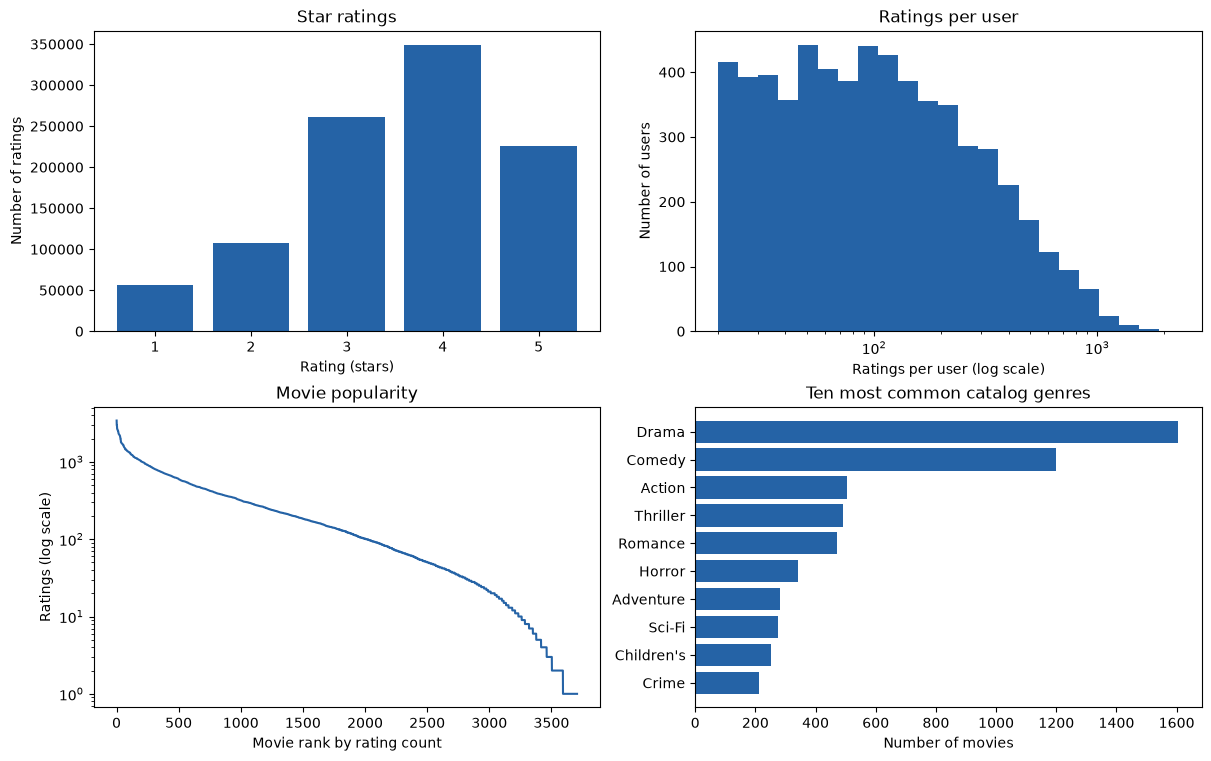

In [6]:
user_counts = interactions.groupby("user_id").size()
movie_counts = interactions.groupby("movie_id").size().sort_values(ascending=False)
rating_counts = interactions["rating"].value_counts().sort_index()
genre_counts = movies["genres"].str.split("|", regex=False).explode().value_counts()
first_day, last_day = pd.to_datetime(
    [interactions["timestamp"].min(), interactions["timestamp"].max()], unit="s", utc=True
).strftime("%Y-%m-%d")
density = len(interactions) / (len(user_counts) * len(movie_counts))

display(pd.Series({
    "Users who rated": f"{len(user_counts):,}",
    "Catalog movies": f"{len(movies):,}",
    "Movies with ratings": f"{len(movie_counts):,}",
    "Catalog movies without ratings": f"{len(movies) - len(movie_counts):,}",
    "Mean rating": f'{interactions["rating"].mean():.2f} / 5',
    "Observed user–movie pairs": f"{density:.2%}",
    "Date range (UTC)": f"{first_day} to {last_day}",
    "Median ratings per user": f"{user_counts.median():.0f}",
    "Median ratings per rated movie": f"{movie_counts.median():.0f}",
}, name="MovieLens 1M"))

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
ax = axes[0, 0]
ax.bar(rating_counts.index, rating_counts.values, color="#2563a6")
ax.set(title="Star ratings", xlabel="Rating (stars)", ylabel="Number of ratings", xticks=rating_counts.index)

ax = axes[0, 1]
ax.hist(user_counts, bins=np.geomspace(user_counts.min(), user_counts.max() + 1, 24), color="#2563a6")
ax.set(title="Ratings per user", xlabel="Ratings per user (log scale)", ylabel="Number of users", xscale="log")

ax = axes[1, 0]
ax.plot(np.arange(1, len(movie_counts) + 1), movie_counts.values, color="#2563a6")
ax.set(title="Movie popularity", xlabel="Movie rank by rating count", ylabel="Ratings (log scale)", yscale="log")

ax = axes[1, 1]
top_genres = genre_counts.head(10).sort_values()
ax.barh(top_genres.index, top_genres.values, color="#2563a6")
ax.set(title="Ten most common catalog genres", xlabel="Number of movies")
plt.show()

In [7]:
top_ten_share = movie_counts.head(10).sum() / len(interactions)
print(
    f"The ten most-rated movies account for {top_ten_share:.1%} of all ratings. "
    f"A typical rated movie has {movie_counts.median():.0f} ratings, "
    f"while the most-rated movie has {movie_counts.iloc[0]:,}."
)

The ten most-rated movies account for 2.8% of all ratings. A typical rated movie has 124 ratings, while the most-rated movie has 3,428.


## 4. Define the two recommenders

**Top-N by popularity.** Rank movies by how many ratings they received in the fit data. Ties go to the lower MovieLens movie ID. For known users, remove movies in their rating history.

**Matrix factorization.** Learn user and movie biases and 24-dimensional latent vectors. The predicted score is the global mean plus the two biases plus the dot product of the vectors. Alternating least squares updates one side at a time with L2 regularization, using observed ratings stored in a sparse matrix. Rank by the raw predicted score and exclude rated movies. A user with no ratings in the fit data gets the popularity list. Both models draw candidates from movies with at least one rating in the fit data.

In [8]:
def rating_history(data):
    return data.groupby("user_id")["movie_id"].agg(set).to_dict()


def rank_unseen(scores, seen, n):
    unseen = scores.loc[~scores.index.isin(seen)]
    return unseen.sort_values(ascending=False, kind="stable").head(n)


def recommend_top_n(user_id, n, popularity, history):
    return rank_unseen(popularity, history.get(user_id, ()), n)


def update_factors(observed, fixed, regularization, mean):
    # Column 0 of each parameter matrix is the bias. The rest are latent factors.
    features = np.column_stack([np.ones(len(fixed)), fixed[:, 1:]])
    penalty = regularization * np.eye(features.shape[1])
    updated = np.empty((observed.shape[0], features.shape[1]))

    for row in range(observed.shape[0]):
        start, stop = observed.indptr[row:row + 2]
        columns = observed.indices[start:stop]
        design = features[columns]
        target = observed.data[start:stop] - mean - fixed[columns, 0]
        updated[row] = np.linalg.solve(
            design.T @ design + penalty,
            design.T @ target,
        )
    return updated


class MatrixFactorization:
    def fit(self, data, factors=24, epochs=12, regularization=3.0, seed=42):
        user_ids = pd.Index(np.sort(data["user_id"].unique()))
        self.movie_ids = pd.Index(np.sort(data["movie_id"].unique()), name="movie_id")
        self.user_rows = {user_id: row for row, user_id in enumerate(user_ids)}
        self.mean = data["rating"].mean()

        user_rows = user_ids.get_indexer(data["user_id"])
        movie_rows = self.movie_ids.get_indexer(data["movie_id"])
        observations = csr_matrix(
            (data["rating"].to_numpy(dtype=float), (user_rows, movie_rows)),
            shape=(len(user_ids), len(self.movie_ids)),
        )
        transposed = observations.T.tocsr()

        rng = np.random.default_rng(seed)
        self.movies = rng.normal(0, 0.1, size=(len(self.movie_ids), factors + 1))
        self.movies[:, 0] = 0.0
        for _ in range(epochs):
            self.users = update_factors(observations, self.movies, regularization, self.mean)
            self.movies = update_factors(transposed, self.users, regularization, self.mean)
        return self

    def score(self, user_id):
        user = self.users[self.user_rows[user_id]]
        scores = self.mean + user[0] + self.movies[:, 0] + self.movies[:, 1:] @ user[1:]
        return pd.Series(scores, index=self.movie_ids, name="predicted_score")


def recommend_mf(user_id, n, model, popularity, history):
    if user_id not in model.user_rows:
        return recommend_top_n(user_id, n, popularity, history)
    return rank_unseen(model.score(user_id), history.get(user_id, ()), n)

## 5. Compare both models on later ratings

Hold out the latest approximately 20% of ratings using one global timestamp cutoff. Ratings at the cutoff go into the holdout together. Fit both models on ratings strictly before the cutoff. Compare them for users and movies present in training so the evaluation measures personalized ranking for users with a rating history.

A held-out score of 4 or 5 counts as relevant. Evaluate each user with at least one relevant held-out movie in the shared candidate pool. Precision@10 is the number of hits divided by 10. Recall@10 is the share of relevant candidates retrieved. NDCG@10 discounts hits lower in the list and normalizes by the ideal ranking. Average each metric across the same users. This is an offline comparison against movies users chose to rate, with no measured preferences for the other unseen movies.

In [9]:
K = 10
cutoff_position = int(0.8 * len(interactions))
cutoff = int(np.sort(interactions["timestamp"].to_numpy())[cutoff_position])
train = interactions.loc[interactions["timestamp"] < cutoff]
test = interactions.loc[interactions["timestamp"] >= cutoff]

popularity = train.groupby("movie_id").size().rename("rating_count")
history = rating_history(train)
model = MatrixFactorization().fit(train)

warm = test["user_id"].isin(history) & test["movie_id"].isin(popularity.index)
relevant = rating_history(test.loc[warm & test["rating"].ge(4)])
print(f"Cutoff (UTC) {pd.to_datetime(cutoff, unit='s', utc=True)}")
print(f"Training ratings {len(train):,} | Holdout ratings {len(test):,} ({len(test) / len(interactions):.1%})")
print(f"Holdout users {test['user_id'].nunique():,} | Holdout users absent from training {(~test['user_id'].drop_duplicates().isin(history)).sum():,}")
print(f"Holdout ratings outside the warm-user, warm-movie pool {(~warm).sum():,}")
print(f"Users with at least one relevant held-out candidate {len(relevant):,}")

Cutoff (UTC) 2000-12-02 14:52:18+00:00
Training ratings 800,164 | Holdout ratings 200,045 (20.0%)
Holdout users 1,783 | Holdout users absent from training 640
Holdout ratings outside the warm-user, warm-movie pool 95,593
Users with at least one relevant held-out candidate 1,122


In [10]:
def evaluate_at_k(recommend, relevant_movies, k):
    discounts = 1 / np.log2(np.arange(2, k + 2))
    rows = []
    for user_id, actual in relevant_movies.items():
        ranked_ids = recommend(user_id, k).index
        hits = ranked_ids.isin(actual)
        dcg = hits @ discounts[:len(hits)]
        ideal_dcg = discounts[:min(k, len(actual))].sum()
        rows.append([hits.sum() / k, hits.sum() / len(actual), dcg / ideal_dcg])
    columns = [f"Precision@{k}", f"Recall@{k}", f"NDCG@{k}"]
    return pd.DataFrame(rows, columns=columns).mean()


results = pd.DataFrame({
    "Top-N popularity": evaluate_at_k(
        lambda user, k: recommend_top_n(user, k, popularity, history), relevant, K
    ),
    "Matrix factorization": evaluate_at_k(
        lambda user, k: recommend_mf(user, k, model, popularity, history), relevant, K
    ),
}).T
display(results.round(4))

,Precision@10,Recall@10,NDCG@10
Top-N popularity,0.1995,0.0493,0.2144
Matrix factorization,0.1280,0.0361,0.1394


## 6. Recommend movies using the full dataset

After evaluation, refit with all available ratings for the final recommendations. Set `USER_ID` to an original MovieLens user ID and `N` to the desired list length. Both lists exclude every movie that user rated in the CSV. An ID absent from the CSV produces the popularity list.

In [11]:
full_popularity = interactions.groupby("movie_id").size().rename("rating_count")
full_history = rating_history(interactions)
full_model = MatrixFactorization().fit(interactions)
catalog = movies.set_index("movie_id")[["title", "genres"]]

USER_ID = 11
N = 10

print(f"Top-N popularity for user {USER_ID}")
display(recommend_top_n(USER_ID, N, full_popularity, full_history).to_frame().join(catalog))

print(f"Matrix factorization for user {USER_ID}")
display(recommend_mf(USER_ID, N, full_model, full_popularity, full_history).round(3).to_frame().join(catalog))

Top-N popularity for user 11


,rating_count,title,genres
movie_id,,,
260,2991,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi
1196,2990,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War
1210,2883,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War
2028,2653,Saving Private Ryan (1998),Action|Drama|War
589,2649,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller
2571,2590,"Matrix, The (1999)",Action|Sci-Fi|Thriller
1270,2583,Back to the Future (1985),Comedy|Sci-Fi
1580,2538,Men in Black (1997),Action|Adventure|Comedy|Sci-Fi
527,2304,Schindler's List (1993),Drama|War


Matrix factorization for user 11


,predicted_score,title,genres
movie_id,,,
2324,5.665,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama
1193,5.082,One Flew Over the Cuckoo's Nest (1975),Drama
58,4.930,"Postino, Il (The Postman) (1994)",Drama|Romance
32,4.768,Twelve Monkeys (1995),Drama|Sci-Fi
1449,4.758,Waiting for Guffman (1996),Comedy
296,4.740,Pulp Fiction (1994),Crime|Drama
627,4.613,"Last Supper, The (1995)",Drama|Thriller
1300,4.610,My Life as a Dog (Mitt liv som hund) (1985),Drama
3896,4.573,"Way of the Gun, The (2000)",Crime|Thriller
